<a href="https://colab.research.google.com/github/AMJAD-CODE/Cloud-computing/blob/main/Lab_4_cloud.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


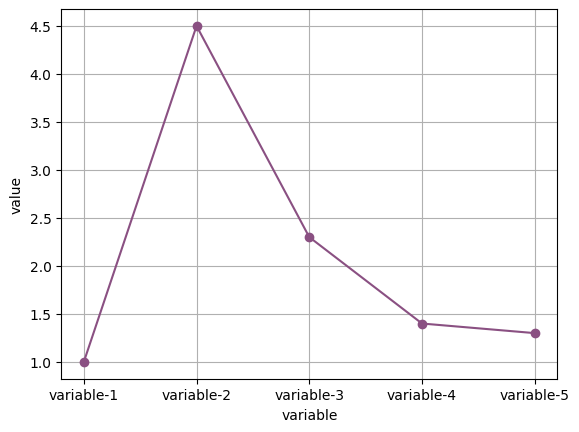

In [98]:
import matplotlib.pyplot as plt
import json
#------------
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
from plotly.offline import iplot
import plotly.graph_objs as go
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns  #seaborn for heatmap

#------------
from google.colab import drive
drive.mount('/content/drive')
dictionary = json.load(open('/content/drive/My Drive/Colab Notebooks/Lab_3/3_1.json', 'r'))

xAxis = [key for key, value in dictionary.items()]
yAxis = [value for key, value in dictionary.items()]
plt.grid(True)

## LINE GRAPH ##
plt.plot(xAxis,yAxis, color='#8a5082', marker='o')
plt.xlabel('variable')
plt.ylabel('value')

plt.show()


In [99]:
import pandas as pd

df2 = pd.read_json('/content/drive/My Drive/Colab Notebooks/Lab_3/3_2.json')

print(df2)


    cars  passings
0    BMW         3
1  Volvo         7
2   Ford         2


In [100]:
import pandas as pd

df2 = pd.read_json('/content/drive/My Drive/Colab Notebooks/Lab_3/3_3.json')

print(df2)


   Duration  Pulse  Maxpulse  Calories
0        60    110       130     409.1
1        60    117       145     479.0
2        60    103       135     340.0
3        45    109       175     282.4
4        45    117       148     406.0
5        60    102       127     300.5


In [101]:
import pandas as pd
import plotly.express as px

# Create a sample dataframe
data = {
    "Country": ["Germany", "France", "Italy", "Spain", "United Kingdom"],
    "GDP": [3.8, 2.7, 1.9, 1.4, 2.1],
    "Population": [83, 67, 60, 47, 66],
    "Vehicles Fleet": [50, 35, 40, 30, 45]
}

df = pd.DataFrame(data)

# Create a scatter matrix
fig = px.scatter_matrix(df,
                        dimensions=["GDP", "Population", "Vehicles Fleet"],
                        color="Country",
                        title="Scatter Matrix: Country GDP, Population, and Vehicles Fleet in Europe")

# Display the scatter matrix
fig.show()


In [102]:
import requests
import pandas as pd
import ipywidgets as widgets

url = 'https://data.gov.il/api/3/action/datastore_search?resource_id=053cea08-09bc-40ec-8f7a-156f0677aff3'


pd.set_option("display.max_columns", None)

response = requests.get(url)

data = response.json()
data_df = pd.DataFrame(data['result']['records'])


data_df.head() #יציג את 5 השורות הראשונות של הנתונים

manufacturer = widgets.Dropdown(
    options=[''] + sorted(data_df['tozeret_nm'].unique()),
    description='Tozeret:'
)

kinuy_mishari = widgets.Dropdown(
    options=[''],
    description='Kinuy Mishari:'
)
output_area = widgets.Output()

# When the manufacturer changes, show only that manufacturer's models
def update_kinuy(change):
    if change['new']:
        models = data_df[data_df['tozeret_nm'] == change['new']]['kinuy_mishari'].unique()
        kinuy_mishari.options = [''] + sorted(models)
    else:
        kinuy_mishari.options = ['']

# When the model changes, print the results
def update_output(change):
    output_area.clear_output()
    t, k = manufacturer.value, kinuy_mishari.value
    with output_area:
        if t and k:
            f = data_df[(data_df['tozeret_nm'] == t) & (data_df['kinuy_mishari'] == k)]
            gimur = f['ramat_gimur'].dropna().unique()
            print(f"Total Records: {len(f)}")
            print(f"Unique Ramat Gimur: {', '.join(gimur) if len(gimur) else 'None'}")

manufacturer.observe(update_kinuy, names='value')
kinuy_mishari.observe(update_output, names='value')

display(widgets.VBox([manufacturer, kinuy_mishari, output_area]))



In [103]:
# Create a simple DataFrame
data = {
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Age': [25, 30, 35],
    'City': ['New York', 'Los Angeles', 'Chicago']
}
df = pd.DataFrame(data)

display(df)



,Name,Age,City
0,Alice,25,New York
1,Bob,30,Los Angeles
2,Charlie,35,Chicago


In [104]:
# Tab 1: Data Overview
tab1_content = widgets.Output()
with tab1_content:
    print("Data Overview:")
    display(df.describe())  # Summary statistics


In [105]:
tab2_content = widgets.Output()
with tab2_content:
    print("Raw Data:")
    display(df)



In [106]:
# Tab 3: Charts
tab3_content = widgets.Output()
with tab3_content:
    print("Charts:")
    plt.clf()  # Clear the current figure
    plt.figure(figsize=(10, 8))  # Increased figure size to accommodate labels
    side_length = 10
    data = 5 + np.random.randn(side_length, side_length)
    data += np.arange(side_length)
    data += np.reshape(np.arange(side_length), (side_length, 1))

    # Create heatmap with labels
    heatmap = sns.heatmap(data,
                         cmap='viridis',
                         annot=True,
                         fmt='.1f',
                         cbar_kws={'label': 'Value Intensity'})
    plt.title('Enhanced Heatmap with Labels')
    plt.xlabel('X Axis Position')
    plt.ylabel('Y Axis Position')
    plt.show()  # Add this to display the plot
    plt.close()  # Close the figure t free memory

    # Create Tabs
tabs = widgets.Tab(children=[tab1_content, tab2_content,tab3_content])
tabs.set_title(0, 'Tab 1: Data Overview')
tabs.set_title(1, 'Tab 2: Raw Data')
tabs.set_title(2, 'Tab 3: Charts')



# Display Tabs
display(tabs)




In [107]:
# Tab 1: Data Overview
tab1_content = widgets.Output()
with tab1_content:
    print("Data Overview:")
    display(data_df.describe())  # Summary statistics


tab2_content = widgets.Output()
with tab2_content:
    print("Raw Data:")
    display(data_df)


# Tab 3: Charts
tab3_content = widgets.Output()
with tab3_content:
    print("Charts:")
    plt.figure(figsize=(10, 8))  # Increased figure size to accommodate labels


    #create bar chart


    amount = data_df['shnat_yitzur'].value_counts().sort_index()

    barchart = plt.bar(amount.index, amount.values)
    plt.title('Enhanced Bar Chart')
    plt.xlabel('X Axis Position')
    plt.ylabel('Y Axis Position')

    plt.show()  # Add this to display the plot
    plt.close()  # Close the figure t free memory



    # Create Tabs
tabs = widgets.Tab(children=[tab1_content, tab2_content,tab3_content])
tabs.set_title(0, 'Tab 1: Data Overview')
tabs.set_title(1, 'Tab 2: Raw Data')
tabs.set_title(2, 'Tab 3: Charts')



# Display Tabs
display(tabs)


